In [210]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from statsmodels.multivariate.factor import Factor
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import iqr as count_iqr
from sklearn.cluster import AgglomerativeClustering
from factor_analyzer.factor_analyzer import calculate_kmo
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity
from sklearn.cluster import KMeans


In [211]:
df = pd.read_excel("DATA.xlsx")

In [212]:
df.columns = ["regions", "income_per_soul", "median_income", 
              "average_wage", "average_pension", "procent_income_from_gove",
              "waste_per_soul", "procent_waste_flats", "procent_waste_culture", 
              "count_dishwashers", "count_cars", "average_area_per_soul", 
              "coef_fonds", "coef_jini", "min_income", 
              "procent_below_min_income", "expected_life_long", "level_of_unemployment", 
              "count_students"]

In [213]:
df["income_per_soul_div_min"] = df["income_per_soul"] / df["min_income"]
df["median_income_div_min"] = df["median_income"] / df["min_income"]
df["average_wage_div_min"] = df["average_wage"] / df["min_income"]
df["average_pension_div_min"] = df["average_pension"] / df["min_income"]

In [214]:
new_df = df[["regions", "median_income_div_min", "average_wage_div_min", "income_per_soul_div_min",
             "count_cars", "average_area_per_soul"]].set_index("regions")

In [215]:
new_df.head()

,median_income_div_min,average_wage_div_min,income_per_soul_div_min,count_cars,average_area_per_soul
regions,,,,,
Белгородская область,2.806278,4.074410,3.508553,336.3,35.0
Брянская область,2.184642,3.108403,2.721262,213.6,32.5
Владимирская область,2.043338,3.383231,2.393971,315.6,31.9
Воронежская область,2.603693,3.911173,3.323107,362.4,33.5
Ивановская область,2.105880,2.840856,2.676480,347.2,30.9


In [216]:
ylabels = ["Раз", "Раз", "Раз", "шт. на 1000 чел.", "кв. м."]
i = 0

for column in new_df.columns:
    plt.figure(figsize = (12, 4))
    new_df.boxplot(column = [column])
    plt.ylabel(ylabels[i])
    plt.savefig(f"boxplots/{i}s.png")
    plt.close()
    i += 1

In [217]:
corr = new_df.corr().round(3)
corr.style.background_gradient()

,median_income_div_min,average_wage_div_min,income_per_soul_div_min,count_cars,average_area_per_soul
median_income_div_min,1.000000,0.738000,0.978000,0.186000,0.287000
average_wage_div_min,0.738000,1.000000,0.765000,0.133000,0.020000
income_per_soul_div_min,0.978000,0.765000,1.000000,0.193000,0.256000
count_cars,0.186000,0.133000,0.193000,1.000000,0.488000
average_area_per_soul,0.287000,0.020000,0.256000,0.488000,1.000000


In [218]:
qrs = []
maxes = []
mines = []
desc_stat = new_df.describe()
desc_stat = desc_stat.T

for column in new_df.columns:
    qrs.append(count_iqr(new_df[column].values))
    maxes.append(new_df[new_df[column] == new_df[column].max()].index[0])
    mines.append(new_df[new_df[column] == new_df[column].min()].index[0])

desc_stat["iqr"] = qrs
desc_stat["spread"] = desc_stat["max"] - desc_stat["min"]
desc_stat["min_region"] = mines
desc_stat["max_region"] = maxes

desc_stat.round(1)

,count,mean,std,min,25%,50%,75%,max,iqr,spread,min_region,max_region
median_income_div_min,82.0,2.2,0.4,1.3,1.9,2.1,2.3,3.6,0.4,2.2,Республика Ингушетия,г. Москва
average_wage_div_min,82.0,3.7,0.8,2.4,3.3,3.7,4.1,6.8,0.8,4.5,Кабардино-Балкарская Республика,Тюменская область
income_per_soul_div_min,82.0,2.7,0.6,1.6,2.4,2.6,2.9,4.6,0.5,3.0,Республика Ингушетия,г. Москва
count_cars,82.0,327.7,75.2,117.3,284.3,328.4,368.8,576.2,84.5,458.9,Чукотский автономный округ,Камчатский край
average_area_per_soul,82.0,28.7,4.4,14.8,26.1,29.0,31.9,36.8,5.8,22.0,Республика Тыва,Псковская область


In [219]:
desc_stat.to_excel("descript_stat.xlsx")

In [220]:
corr.to_excel("correlation.xlsx")

In [221]:
std_df = new_df.copy()

for col in std_df.columns:
    std_df[col] = (std_df[col] - std_df[col].mean()) / std_df[col].std()

In [222]:
chi_square_value, p_value = calculate_bartlett_sphericity(std_df)
chi_square_value, p_value

(354.5623208065004, 4.286111362503527e-70)

In [223]:
kmo_all, kmo_model = calculate_kmo(std_df)
kmo_model

0.6519572761961143

In [224]:
fa = Factor(std_df, n_factor = 5, method = "pa")
res = fa.fit()

In [225]:
res.rotate(method = "varimax")
res.get_loadings_frame(threshold=0)

,factor 0,factor 1,factor 2,factor 3
median_income_div_min,0.989016,-0.146981,-0.018747,0.097294
income_per_soul_div_min,0.981411,-0.124997,0.053110,-0.100678
average_wage_div_min,0.765428,0.069681,0.412932,-0.006738
average_area_per_soul,0.171854,-0.768256,-0.140279,0.012167
count_cars,0.096743,-0.660658,0.253612,-0.021430


In [244]:
sum(sorted(res.eigenvals)[3:])/sum(res.eigenvals)*100

94.24607598958727

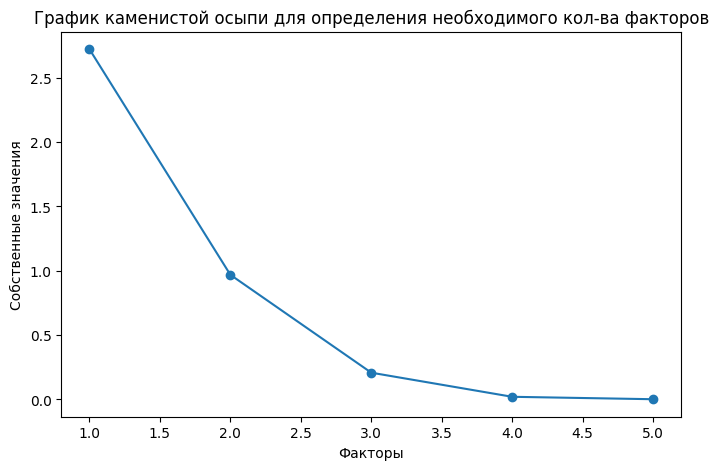

In [226]:
plt.close()

plt.figure(figsize=(8, 5))
plt.scatter(range(1,std_df.shape[1]+1), res.eigenvals)
plt.plot(range(1,std_df.shape[1]+1), res.eigenvals)
plt.title('График каменистой осыпи для определения необходимого кол-ва факторов')
plt.xlabel('Факторы')
plt.ylabel('Собственные значения')

plt.savefig("stones_scree.png")

In [247]:
res.loadings

array([[ 0.98901594, -0.14698098, -0.01874723,  0.09729418],
       [ 0.76542754,  0.06968099,  0.41293187, -0.00673832],
       [ 0.98141122, -0.12499654,  0.05311034, -0.10067761],
       [ 0.0967428 , -0.66065821,  0.25361229, -0.02142995],
       [ 0.17185418, -0.76825588, -0.14027946,  0.01216741]])

In [227]:
load

array([[ 0.98901594,  0.14698098],
       [ 0.76542754, -0.06968099],
       [ 0.98141122,  0.12499654],
       [ 0.0967428 ,  0.66065821],
       [ 0.17185418,  0.76825588]])

In [228]:
load = np.array([res.loadings.T[0], res.loadings.T[1] * (-1)]).T
pces = np.dot(std_df, load)
pc1 = []
pc2 = []

for i in pces:
    print
    pc1.append(i[0])
    pc2.append(i[1])

data = {"regions": std_df.index, "f1": pc1, "f2": pc2}

integral_char = pd.DataFrame(data)
integral_char = integral_char.set_index("regions")

In [229]:
sk_ac = AgglomerativeClustering(n_clusters=3, linkage='ward')
sk_ac_pred_res = sk_ac.fit_predict(integral_char)

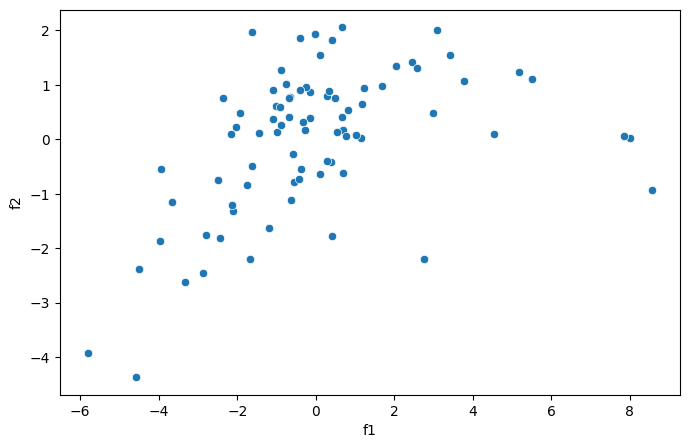

In [230]:
plt.close()

plt.figure(figsize=(8, 5))

sns.scatterplot(data = integral_char, x = "f1", y = "f2")

plt.savefig("ward_scatter.png")

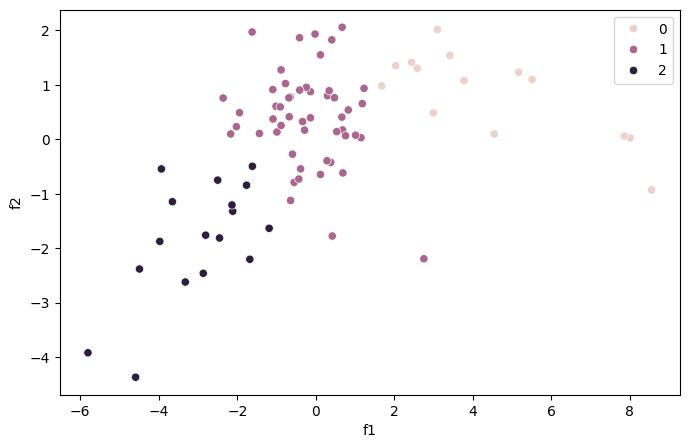

In [231]:
plt.close()

plt.figure(figsize=(8, 5))

sns.scatterplot(data = integral_char, x = "f1", y = "f2", hue = sk_ac_pred_res)

plt.savefig("ward_scatter_clusters.png")

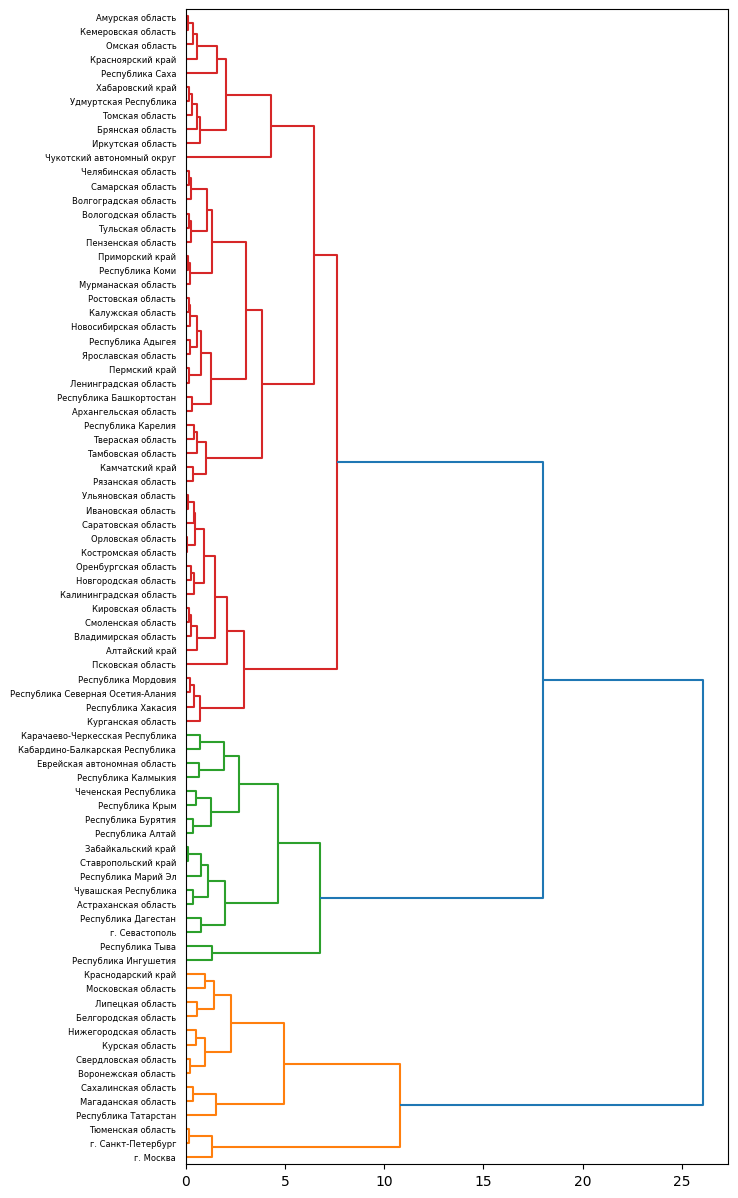

In [232]:
Z = linkage(integral_char, method='ward', metric='euclidean')

plt.close()
plt.figure(figsize=(7, 15))
dendrogram(Z, color_threshold=15, orientation="right", labels = integral_char.index)
plt.savefig("ward_dendro.png")

In [233]:
integral_char["class"] = sk_ac_pred_res
integral_char.to_excel("ward_clusters.xlsx")

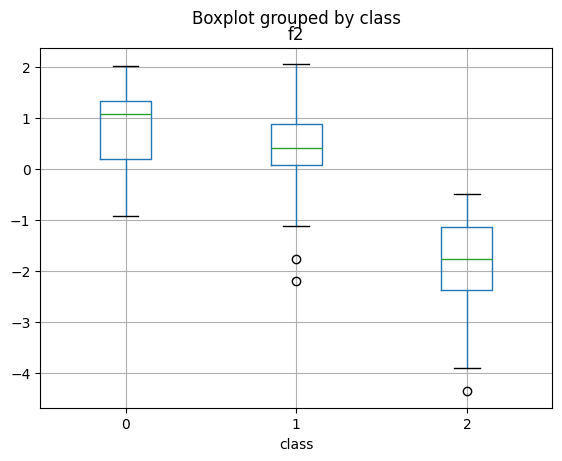

In [234]:
plt.close()
integral_char.boxplot(column="f1", by = "class")
plt.savefig("boxplots/ward_pc1_clust_boxs.png")

plt.close()
integral_char.boxplot(column="f2", by = "class")
plt.savefig("boxplots/ward_pc2_clust_boxs.png")

In [235]:
kmeans = KMeans(n_clusters=3)
k_means_predict = kmeans.fit_predict(integral_char)

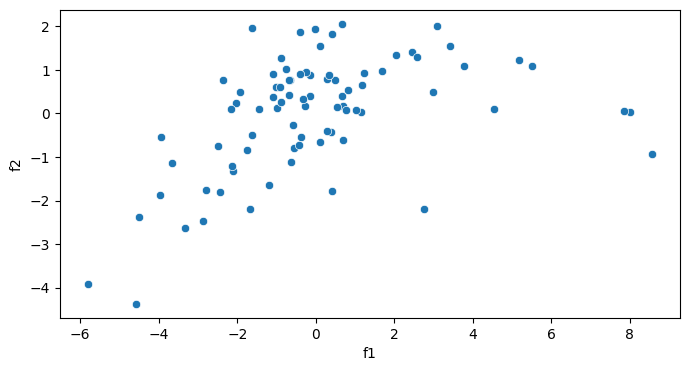

In [236]:
plt.close()
plt.figure(figsize=(8,4))
sns.scatterplot(data = integral_char, x = "f1", y = "f2")
plt.savefig("kmeans_scatter.png")

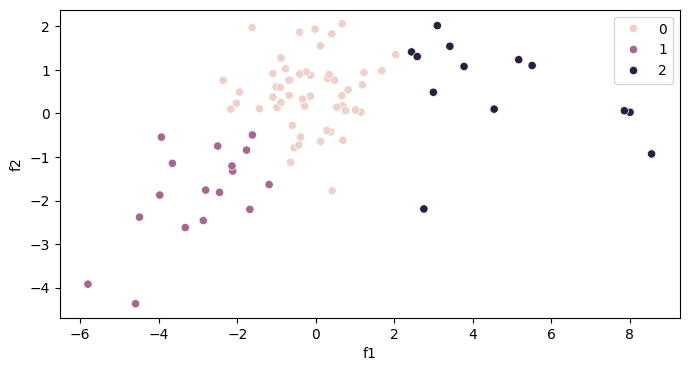

In [237]:
plt.close()
plt.figure(figsize=(8,4))
sns.scatterplot(data = integral_char, x = "f1", y = "f2", hue = k_means_predict)
plt.savefig("kmeans_scatter_clusters.png")

In [238]:
integral_char["class"] = k_means_predict
integral_char.to_excel("kmeans_clusters.xlsx")


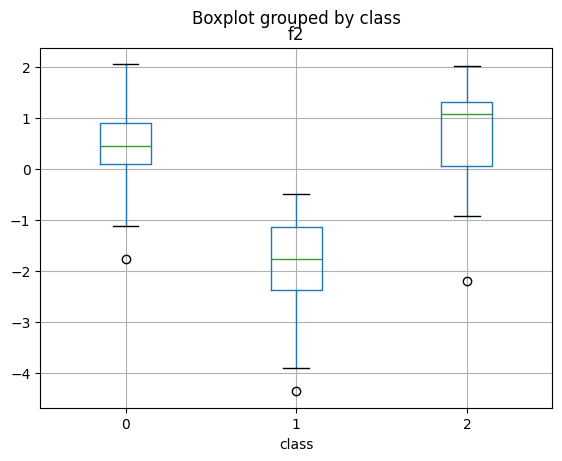

In [239]:
plt.close()
integral_char.boxplot(column="f1", by = "class")
plt.savefig("boxplots/kmeans_pc1_clust_boxs.png")

plt.close()
integral_char.boxplot(column="f2", by = "class")
plt.savefig("boxplots/kmeans_pc2_clust_boxs.png")